# VoltAhead — Data Preprocessing & Feature Engineering

## Step 2: Machine Learning Dataset Preparation

**Objective:** Prepare a validated and reproducible dataset for predicting EV charging station availability 30, 40, and 60 minutes into the future.

In [69]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_loader as dl

TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

for directory in [TABLES_DIR, FIGURES_DIR, PROCESSED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: /Users/zumra/Desktop/classes/26-27/fall 2026/ISE308/VoltAhead


In [70]:
# Load the shared 100-station dataset
df = dl.load_data(columns=["idle", "busy"])

# Attach station metadata
df = dl.attach_station_info(df)

# Ensure chronological ordering within each station
df = df.sort_index()

print("Dataset shape:", df.shape)
print("Number of stations:",
      df.index.get_level_values("station_id").nunique())

display(df.head())

Dataset shape: (2592000, 9)
Number of stations: 100


idle  busy   longitude   latitude  slow_count  \
station_id time                                                                 
1703       2022-12-01 00:00:00   2.0   0.0  114.029918  22.534794           2   
           2022-12-01 00:05:00   2.0   0.0  114.029918  22.534794           2   
           2022-12-01 00:10:00   2.0   0.0  114.029918  22.534794           2   
           2022-12-01 00:15:00   2.0   0.0  114.029918  22.534794           2   
           2022-12-01 00:20:00   2.0   0.0  114.029918  22.534794           2   

                                fast_count  charge_count  TAZID  distance_km  
station_id time                                                               
1703       2022-12-01 00:00:00           0             2    227     2.142178  
           2022-12-01 00:05:00           0             2    227     2.142178  
           2022-12-01 00:10:00           0             2    227     2.142178  
           2022-12-01 00:15:00           0             2    227     2.142178  
           2022-12-01 00:20:00           0             2    227     2.142178

## 2. Initial Dataset Validation

**Objective:** Verify the structure, temporal consistency, station coverage, and missing observations of the shared dataset before preprocessing.

In [71]:
# Dataset structure
n_stations = df.index.get_level_values("station_id").nunique()
n_rows = len(df)

# Timestamp information
timestamps = df.index.get_level_values("time")

start_date = timestamps.min()
end_date = timestamps.max()

# Expected number of observations
expected_timestamps = len(dl.expected_index())
expected_rows = n_stations * expected_timestamps

# Missing observations
missing_idle = df["idle"].isna().sum()
valid_idle = df["idle"].notna().sum()
missing_rate = missing_idle / n_rows * 100

# Structural validation
duplicate_rows = df.index.duplicated().sum()
station_ids_match = (
    set(df.index.get_level_values("station_id").unique())
    == set(dl.list_station_ids())
)

validation_summary = pd.DataFrame({
    "Property": [
        "Number of Stations",
        "Total Observations",
        "Expected Observations",
        "Timestamps per Station",
        "Start Date",
        "End Date",
        "Missing Idle Observations",
        "Valid Idle Observations",
        "Missing Observation Rate (%)",
        "Duplicate Station-Time Rows",
        "Station IDs Match Shared List"
    ],
    "Value": [
        n_stations,
        n_rows,
        expected_rows,
        expected_timestamps,
        str(start_date),
        str(end_date),
        missing_idle,
        valid_idle,
        round(missing_rate, 2),
        duplicate_rows,
        station_ids_match
    ]
})

display(validation_summary)

# Save initial dataset validation summary
validation_summary.to_csv(
    TABLES_DIR / "initial_validation_summary.csv",
    index=False
)

,Property,Value
0,Number of Stations,100
1,Total Observations,2592000
2,Expected Observations,2592000
3,Timestamps per Station,25920
4,Start Date,2022-12-01 00:00:00
5,End Date,2023-02-28 23:55:00
6,Missing Idle Observations,660016
7,Valid Idle Observations,1931984
8,Missing Observation Rate (%),25.46
9,Duplicate Station-Time Rows,0


## 3. Data Consistency Validation

**Objective:** Identify invalid or inconsistent charging observations by checking missing values, negative values, station capacity constraints, and the relationship between idle and busy chargers.

In [72]:
# Check missing charging observations
missing_both = (
    df["idle"].isna() & df["busy"].isna()
).sum()

partial_missing = (
    df["idle"].isna() ^ df["busy"].isna()
).sum()

# Identify observations with both charging values present
observed = df["idle"].notna() & df["busy"].notna()

# Check station capacity
invalid_capacity = (
    df["charge_count"].isna() |
    (df["charge_count"] <= 0)
)

# Check negative values
negative_values = (
    observed &
    ((df["idle"] < 0) | (df["busy"] < 0))
)

# Check values exceeding station capacity
exceeds_capacity = (
    observed &
    (
        (df["idle"] > df["charge_count"]) |
        (df["busy"] > df["charge_count"])
    )
)

# Check idle + busy consistency
capacity_mismatch = (
    observed &
    ~invalid_capacity &
    ((df["idle"] + df["busy"]) != df["charge_count"])
)

# Prepare validation summary
consistency_summary = pd.DataFrame({
    "Check": [
        "Both Idle and Busy Missing",
        "Partially Missing Observations",
        "Invalid Station Capacity",
        "Negative Idle or Busy",
        "Idle or Busy Exceeds Capacity",
        "Idle + Busy != Capacity"
    ],
    "Count": [
        missing_both,
        partial_missing,
        invalid_capacity.sum(),
        negative_values.sum(),
        exceeds_capacity.sum(),
        capacity_mismatch.sum()
    ]
})

# Display results
display(consistency_summary)

# Save results
consistency_summary.to_csv(
    TABLES_DIR / "data_consistency_summary.csv",
    index=False
)

,Check,Count
0,Both Idle and Busy Missing,660016
1,Partially Missing Observations,0
2,Invalid Station Capacity,0
3,Negative Idle or Busy,0
4,Idle or Busy Exceeds Capacity,0
5,Idle + Busy != Capacity,0


### Key Findings — Data Consistency

- A total of **660,016 observations (25.46%)** contain missing idle and busy values.
- No partially missing charging observations were detected.
- All station capacities are positive and valid.
- No negative charger counts or values exceeding station capacity were identified.
- All observations with valid idle and busy values satisfy the constraint `idle + busy = charge_count`.

**Preprocessing Decision:** Missing observations will be preserved as NaN during feature engineering and target generation. No interpolation or missing-value imputation will be applied at this stage.

## 4. Feature Engineering

**Objective:** Generate temporal, station-related, and historical features to predict future EV charging station availability.

### 4.1. Temporal Features

Temporal features capture daily and weekly charging usage patterns identified during exploratory data analysis.

In [73]:
# Extract timestamps from the MultiIndex
time = df.index.get_level_values("time")

# Extract hour of the day (0–23)
df["hour"] = time.hour

# Extract day of the week (Monday=0, Sunday=6)
df["day_of_week"] = time.day_of_week

# Identify weekends (Saturday and Sunday)
df["is_weekend"] = (time.day_of_week >= 5).astype(int)

# Display temporal features
display(
    df[["hour", "day_of_week", "is_weekend"]].head(10)
)

# Validate feature ranges
print("Hour range:", df["hour"].min(), "-", df["hour"].max())
print("Day of week range:", df["day_of_week"].min(), "-", df["day_of_week"].max())
print("Weekend values:", sorted(df["is_weekend"].unique()))

hour  day_of_week  is_weekend
station_id time                                              
1703       2022-12-01 00:00:00     0            3           0
           2022-12-01 00:05:00     0            3           0
           2022-12-01 00:10:00     0            3           0
           2022-12-01 00:15:00     0            3           0
           2022-12-01 00:20:00     0            3           0
           2022-12-01 00:25:00     0            3           0
           2022-12-01 00:30:00     0            3           0
           2022-12-01 00:35:00     0            3           0
           2022-12-01 00:40:00     0            3           0
           2022-12-01 00:45:00     0            3           0

Hour range: 0 - 23
Day of week range: 0 - 6
Weekend values: [np.int64(0), np.int64(1)]


### 4.2. Current Station Features

**Objective:** Generate features representing the current availability, utilization, and total charging capacity of each station.

In [74]:
# Create current station features
df["current_idle"] = df["idle"]
df["current_busy"] = df["busy"]
df["station_capacity"] = df["charge_count"]

# Calculate current occupancy rate
df["occupancy_rate"] = (
    df["current_busy"]
    / df["station_capacity"].where(df["station_capacity"] > 0)
)

# Validate occupancy rate
invalid_occupancy = (
    df["occupancy_rate"].notna()
    & ~df["occupancy_rate"].between(0, 1)
).sum()

# Prepare feature validation summary
station_feature_summary = pd.DataFrame({
    "Feature": [
        "current_idle",
        "current_busy",
        "station_capacity",
        "occupancy_rate"
    ],
    "Missing Values": [
        df["current_idle"].isna().sum(),
        df["current_busy"].isna().sum(),
        df["station_capacity"].isna().sum(),
        df["occupancy_rate"].isna().sum()
    ],
    "Minimum": [
        df["current_idle"].min(),
        df["current_busy"].min(),
        df["station_capacity"].min(),
        df["occupancy_rate"].min()
    ],
    "Maximum": [
        df["current_idle"].max(),
        df["current_busy"].max(),
        df["station_capacity"].max(),
        df["occupancy_rate"].max()
    ]
})

# Display validation summary
display(station_feature_summary)

print("Invalid occupancy rates:", invalid_occupancy)

# Save validation summary as CSV
station_feature_summary.to_csv(
    TABLES_DIR / "station_feature_summary.csv",
    index=False
)

,Feature,Missing Values,Minimum,Maximum
0,current_idle,660016,0.0,54.0
1,current_busy,660016,0.0,41.0
2,station_capacity,0,1.0,54.0
3,occupancy_rate,660016,0.0,1.0


Invalid occupancy rates: 0


### 4.3. Historical Lag Features

**Objective:** Generate historical idle charger counts at 5, 10, 15, 30, 40, 60, and 120-minute intervals.

Lag features capture temporal dependencies in charging station availability. Each lag is calculated independently for each station using the complete 5-minute timestamp grid.

Missing observations are preserved as NaN to avoid introducing artificial charging availability values.

In [75]:
# Define historical lag intervals in minutes
lag_intervals = [5, 10, 15, 30, 40, 60, 120]

# Generate lag features separately for each station
for lag in lag_intervals:
    df[f"idle_lag_{lag}"] = (
        df.groupby(level="station_id")["idle"]
        .shift(lag // 5)
    )

# Prepare lag feature validation summary
lag_summary = pd.DataFrame({
    "Lag (minutes)": lag_intervals,
    "Feature": [f"idle_lag_{lag}" for lag in lag_intervals],
    "Missing Values": [
        df[f"idle_lag_{lag}"].isna().sum()
        for lag in lag_intervals
    ],
    "Valid Observations": [
        df[f"idle_lag_{lag}"].notna().sum()
        for lag in lag_intervals
    ]
})

lag_summary["Missing Rate (%)"] = (
    lag_summary["Missing Values"] / len(df) * 100
)

# Display results
display(lag_summary.round(2))

# Save lag validation summary
lag_summary.round(2).to_csv(
    TABLES_DIR / "lag_feature_summary.csv",
    index=False
)

,Lag (minutes),Feature,Missing Values,Valid Observations,Missing Rate (%)
0,5,idle_lag_5,660068,1931932,25.47
1,10,idle_lag_10,660120,1931880,25.47
2,15,idle_lag_15,660172,1931828,25.47
3,30,idle_lag_30,660328,1931672,25.48
4,40,idle_lag_40,660432,1931568,25.48
5,60,idle_lag_60,660640,1931360,25.49
6,120,idle_lag_120,661264,1930736,25.51


In [76]:
# Verify lag alignment against the original idle series
lag_checks = []

for lag in lag_intervals:
    actual = df[f"idle_lag_{lag}"]

    expected = (
        df.groupby(level="station_id")["idle"]
        .shift(lag // 5)
    )

    mismatches = (
        ~(actual.eq(expected) | (actual.isna() & expected.isna()))
    ).sum()

    lag_checks.append({
        "Lag (minutes)": lag,
        "Alignment Mismatches": int(mismatches)
    })

lag_validation = pd.DataFrame(lag_checks)

display(lag_validation)

# Save validation results
lag_validation.to_csv(
    TABLES_DIR / "lag_alignment_validation.csv",
    index=False
)

,Lag (minutes),Alignment Mismatches
0,5,0
1,10,0
2,15,0
3,30,0
4,40,0
5,60,0
6,120,0


## 5. Target Label Generation

**Objective:** Generate binary availability labels for 30, 40, and 60-minute prediction horizons.

A target value of 1 indicates that at least one charger will be available at the future timestamp. A target value of 0 indicates that no chargers will be available.

Missing future observations are preserved as NaN rather than being classified as unavailable.

In [77]:
# Define prediction horizons in minutes
prediction_horizons = [30, 40, 60]

# Generate future availability targets for each station
for horizon in prediction_horizons:

    # Retrieve future idle count
    future_idle = (
        df.groupby(level="station_id")["idle"]
        .shift(-(horizon // 5))
    )

    # Assign binary target while preserving missing values
    df[f"target_{horizon}"] = (
        (future_idle > 0)
        .astype(float)
        .where(future_idle.notna())
    )

# Summarize target distributions
target_summary = []

for horizon in prediction_horizons:
    target = df[f"target_{horizon}"]

    target_summary.append({
        "Prediction Horizon (min)": horizon,
        "Available (1)": int((target == 1).sum()),
        "Unavailable (0)": int((target == 0).sum()),
        "Missing Targets": int(target.isna().sum()),
        "Available Rate (%)": round(
            (target == 1).sum() / target.notna().sum() * 100, 2
        )
    })

target_summary = pd.DataFrame(target_summary)

# Display target distribution
display(target_summary)

# Save target distribution summary
target_summary.to_csv(
    TABLES_DIR / "target_generation_summary.csv",
    index=False
)

,Prediction Horizon (min),Available (1),Unavailable (0),Missing Targets,Available Rate (%)
0,30,1854805,76633,660562,96.03
1,40,1854629,76627,660744,96.03
2,60,1854277,76615,661108,96.03


## 6. Horizon-Based Dataset Structure

**Objective:** Transform the dataset into a horizon-based format where each station-time observation can generate separate prediction examples for 30, 40, and 60-minute horizons.

Each example contains the prediction timestamp, target timestamp, prediction horizon, input features, and corresponding binary availability target.

In [78]:
# Define candidate input features
feature_columns = [
    "station_id",
    "hour",
    "day_of_week",
    "is_weekend",
    "current_idle",
    "current_busy",
    "station_capacity",
    "occupancy_rate",
    "idle_lag_5",
    "idle_lag_10",
    "idle_lag_15",
    "idle_lag_30",
    "idle_lag_40",
    "idle_lag_60",
    "idle_lag_120",
    "prediction_horizon"
]

# Prepare base dataset
base_df = df.reset_index()

# Generate one dataset per prediction horizon
horizon_datasets = []

for horizon in prediction_horizons:

    horizon_df = base_df[
        [
            "station_id",
            "time",
            "hour",
            "day_of_week",
            "is_weekend",
            "current_idle",
            "current_busy",
            "station_capacity",
            "occupancy_rate",
            "idle_lag_5",
            "idle_lag_10",
            "idle_lag_15",
            "idle_lag_30",
            "idle_lag_40",
            "idle_lag_60",
            "idle_lag_120",
            f"target_{horizon}"
        ]
    ].copy()

    horizon_df["prediction_horizon"] = horizon

    horizon_df["target_time"] = (
        horizon_df["time"]
        + pd.to_timedelta(horizon, unit="min")
    )

    horizon_df = horizon_df.rename(
        columns={f"target_{horizon}": "target"}
    )

    horizon_datasets.append(horizon_df)

# Combine all prediction horizons
model_df = pd.concat(
    horizon_datasets,
    ignore_index=True
)

# Arrange columns
model_df = model_df[
    ["station_id", "time", "target_time"]
    + [col for col in feature_columns if col != "station_id"]
    + ["target"]
]

# Validate horizon-based structure
horizon_structure_summary = (
    model_df.groupby("prediction_horizon")
    .agg(
        Observations=("target", "size"),
        Valid_Targets=("target", "count"),
        Missing_Targets=("target", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(horizon_structure_summary)

print("Total prediction examples:", len(model_df))
print("Number of input features:", len(feature_columns))

# Save structure summary as CSV
horizon_structure_summary.to_csv(
    TABLES_DIR / "horizon_structure_summary.csv",
    index=False
)

,prediction_horizon,Observations,Valid_Targets,Missing_Targets
0,30,2592000,1931438,660562
1,40,2592000,1931256,660744
2,60,2592000,1930892,661108


Total prediction examples: 7776000
Number of input features: 16


## 7. Missing Values Handling

**Objective:** Evaluate the impact of missing current observations, target labels, and historical lag features on the model-ready dataset.

### 7.1. Complete-Case Analysis

The complete-case approach retains only observations with valid current station features, target labels, and all historical lag features.

Data loss and unavailable class retention are evaluated before selecting the final missing-value strategy.

In [79]:
# Define required current and lag features
current_features = [
    "current_idle",
    "current_busy",
    "station_capacity",
    "occupancy_rate"
]

lag_features = [
    f"idle_lag_{lag}" for lag in lag_intervals
]

# Check valid current observations
valid_current = (
    model_df[current_features].notna().all(axis=1)
    & (model_df["station_capacity"] > 0)
    & model_df["occupancy_rate"].between(0, 1)
)

# Check valid target labels
valid_target = model_df["target"].isin([0, 1])

# Check complete historical lag features
valid_lags = model_df[lag_features].notna().all(axis=1)

# Sequential filtering masks
after_current = valid_current
after_target = after_current & valid_target
complete_case_mask = after_target & valid_lags

# Calculate data loss for each prediction horizon
missing_analysis = []

for horizon in prediction_horizons:

    horizon_mask = model_df["prediction_horizon"] == horizon

    initial_count = int(horizon_mask.sum())
    current_count = int((horizon_mask & after_current).sum())
    target_count = int((horizon_mask & after_target).sum())
    final_count = int((horizon_mask & complete_case_mask).sum())

    unavailable_count = int((
        horizon_mask
        & complete_case_mask
        & (model_df["target"] == 0)
    ).sum())

    missing_analysis.append({
        "Horizon (min)": horizon,
        "Initial Observations": initial_count,
        "Removed - Current": initial_count - current_count,
        "Removed - Target": current_count - target_count,
        "Removed - Lags": target_count - final_count,
        "Remaining Observations": final_count,
        "Remaining Unavailable (0)": unavailable_count,
        "Data Retained (%)": round(
            final_count / initial_count * 100, 2
        )
    })

missing_analysis = pd.DataFrame(missing_analysis)

# Display results
display(missing_analysis)

# Save analysis as CSV
missing_analysis.to_csv(
    TABLES_DIR / "complete_case_analysis.csv",
    index=False
)

,Horizon (min),Initial Observations,Removed - Current,Removed - Target,Removed - Lags,Remaining Observations,Remaining Unavailable (0),Data Retained (%)
0,30,2592000,660016,2717,8014,1921253,75888,74.12
1,40,2592000,660016,3605,7615,1920764,75861,74.10
2,60,2592000,660016,5360,6762,1919862,75809,74.07


### 7.2. Missing-Aware vs. Complete-Case Comparison

**Objective:** Compare the number of usable observations and unavailable-class examples under complete-case and missing-aware preprocessing strategies.

The missing-aware approach retains observations with valid current features and target labels, even when historical lag features are missing.

In [80]:
# Compare complete-case and missing-aware strategies
strategy_results = []

for horizon in prediction_horizons:

    horizon_mask = (
        model_df["prediction_horizon"] == horizon
    )

    # Missing-aware: require current features and target only
    missing_aware_mask = horizon_mask & after_target

    # Complete-case: additionally require all lag features
    complete_mask = horizon_mask & complete_case_mask

    missing_aware_count = int(missing_aware_mask.sum())
    complete_count = int(complete_mask.sum())

    missing_aware_unavailable = int(
        (missing_aware_mask & (model_df["target"] == 0)).sum()
    )

    complete_unavailable = int(
        (complete_mask & (model_df["target"] == 0)).sum()
    )

    strategy_results.append({
        "Horizon (min)": horizon,
        "Missing-Aware Observations": missing_aware_count,
        "Complete-Case Observations": complete_count,
        "Additional Observations": missing_aware_count - complete_count,
        "Missing-Aware Unavailable (0)": missing_aware_unavailable,
        "Complete-Case Unavailable (0)": complete_unavailable,
        "Additional Unavailable (0)": (
            missing_aware_unavailable - complete_unavailable
        )
    })

strategy_comparison = pd.DataFrame(strategy_results)

# Display results
display(strategy_comparison)

# Save comparison table
strategy_comparison.to_csv(
    TABLES_DIR / "missing_strategy_comparison.csv",
    index=False
)

,Horizon (min),Missing-Aware Observations,Complete-Case Observations,Additional Observations,Missing-Aware Unavailable (0),Complete-Case Unavailable (0),Additional Unavailable (0)
0,30,1929267,1921253,8014,76443,75888,555
1,40,1928379,1920764,7615,76396,75861,535
2,60,1926624,1919862,6762,76298,75809,489


## 8. Dataset Period Comparison

**Objective:** Compare the full 90-day dataset with a 52-day higher-coverage period to evaluate data availability, retained observations, station coverage, and target class distribution.

The final dataset period will be selected based on data quality and coverage rather than test-set model performance.

In [81]:
# Define candidate dataset periods
dataset_periods = {
    "Full Dataset (90 days)": (
        pd.Timestamp("2022-12-01"),
        pd.Timestamp("2023-03-01")
    ),
    "Higher Coverage (52 days)": (
        pd.Timestamp("2022-12-01"),
        pd.Timestamp("2023-01-22")
    )
}

# Prepare period comparison results
period_results = []

for period_name, (start, end) in dataset_periods.items():

    # Original station-time observations within the period
    base_mask = (
        (df.index.get_level_values("time") >= start)
        & (df.index.get_level_values("time") < end)
    )

    period_base = df.loc[base_mask]

    valid_base = (
        period_base["idle"].notna()
        & period_base["busy"].notna()
    )

    # Model examples must have prediction and target times
    # inside the selected period
    period_mask = (
        model_df["time"].ge(start)
        & model_df["time"].lt(end)
        & model_df["target_time"].lt(end)
    )

    for horizon in prediction_horizons:

        horizon_mask = (
            period_mask
            & model_df["prediction_horizon"].eq(horizon)
        )

        complete_mask = horizon_mask & complete_case_mask

        period_results.append({
            "Dataset Period": period_name,
            "Horizon (min)": horizon,
            "Base Observations": len(period_base),
            "Valid Base Observations": int(valid_base.sum()),
            "Missing Rate (%)": round(
                (1 - valid_base.mean()) * 100, 2
            ),
            "Complete-Case Examples": int(complete_mask.sum()),
            "Available (1)": int((
                complete_mask & model_df["target"].eq(1)
            ).sum()),
            "Unavailable (0)": int((
                complete_mask & model_df["target"].eq(0)
            ).sum()),
            "Remaining Stations": model_df.loc[
                complete_mask, "station_id"
            ].nunique()
        })

# Create comparison table
period_comparison = pd.DataFrame(period_results)

# Display results
display(period_comparison)

# Save comparison as CSV
period_comparison.to_csv(
    TABLES_DIR / "dataset_period_comparison.csv",
    index=False
)

,Dataset Period,Horizon (min),Base Observations,Valid Base Observations,Missing Rate (%),Complete-Case Examples,Available (1),Unavailable (0),Remaining Stations
0,Full Dataset (90 days),30,2592000,1931984,25.46,1921253,1845365,75888,99
1,Full Dataset (90 days),40,2592000,1931984,25.46,1920764,1844903,75861,99
2,Full Dataset (90 days),60,2592000,1931984,25.46,1919862,1844053,75809,99
3,Higher Coverage (52 days),30,1497600,1351021,9.79,1347719,1287256,60463,93
4,Higher Coverage (52 days),40,1497600,1351021,9.79,1347524,1287064,60460,93
5,Higher Coverage (52 days),60,1497600,1351021,9.79,1347139,1286688,60451,93


## 9. Chronological Train/Validation/Test Split

**Objective:** Evaluate chronological train, validation, and test splits for both candidate dataset periods.

An approximate 70/15/15 chronological split is considered. Prediction timestamps and target timestamps must remain within their assigned split boundaries to prevent data leakage.

Final split boundaries will be selected after evaluating observation counts, station coverage, and target class distributions.

In [82]:
# Define candidate chronological split boundaries
split_options = {
    "Full Dataset (90 days)": {
        "Train": ("2022-12-01", "2023-02-02"),
        "Validation": ("2023-02-02", "2023-02-15"),
        "Test": ("2023-02-15", "2023-03-01")
    },
    "Higher Coverage (52 days)": {
        "Train": ("2022-12-01", "2023-01-06"),
        "Validation": ("2023-01-06", "2023-01-14"),
        "Test": ("2023-01-14", "2023-01-22")
    }
}

# Evaluate candidate splits without modifying the dataset
split_results = []

for period_name, splits in split_options.items():

    for split_name, (start, end) in splits.items():

        start = pd.Timestamp(start)
        end = pd.Timestamp(end)

        # Keep prediction and target times inside the same split
        time_mask = (
            model_df["time"].ge(start)
            & model_df["time"].lt(end)
            & model_df["target_time"].lt(end)
        )

        for horizon in prediction_horizons:

            mask = (
                time_mask
                & model_df["prediction_horizon"].eq(horizon)
                & complete_case_mask
            )

            subset = model_df.loc[
                mask, ["station_id", "target"]
            ]

            available = int((subset["target"] == 1).sum())
            unavailable = int((subset["target"] == 0).sum())
            total = len(subset)

            split_results.append({
                "Dataset Period": period_name,
                "Split": split_name,
                "Horizon (min)": horizon,
                "Observations": total,
                "Stations": subset["station_id"].nunique(),
                "Available (1)": available,
                "Unavailable (0)": unavailable,
                "Unavailable Rate (%)": round(
                    unavailable / total * 100, 2
                ) if total > 0 else np.nan
            })

# Prepare results table
split_comparison = pd.DataFrame(split_results)

# Display comparison
display(split_comparison)

# Save comparison as CSV
split_comparison.to_csv(
    TABLES_DIR / "chronological_split_comparison.csv",
    index=False
)

,Dataset Period,Split,Horizon (min),Observations,Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,Full Dataset (90 days),Train,30,1513165,93,1447874,65291,4.31
1,Full Dataset (90 days),Train,40,1512968,93,1447680,65288,4.32
2,Full Dataset (90 days),Train,60,1512579,93,1447300,65279,4.32
3,Full Dataset (90 days),Validation,30,195941,94,191180,4761,2.43
4,Full Dataset (90 days),Validation,40,195637,94,190896,4741,2.42
5,Full Dataset (90 days),Validation,60,195100,94,190393,4707,2.41
6,Full Dataset (90 days),Test,30,211523,98,205699,5824,2.75
7,Full Dataset (90 days),Test,40,211327,98,205511,5816,2.75
8,Full Dataset (90 days),Test,60,210935,98,205136,5799,2.75
9,Higher Coverage (52 days),Train,30,933098,91,890169,42929,4.60


### 9.2. Split Coverage and Actual Ratios

**Objective:** Evaluate data coverage and the actual distribution of usable prediction examples across chronological splits for both candidate dataset periods.

In [83]:
# Evaluate data coverage and actual split ratios
split_coverage_results = []

for period_name, splits in split_options.items():

    # Use the 30-minute horizon for split ratio comparison
    horizon_30 = split_comparison[
        (split_comparison["Dataset Period"] == period_name)
        & (split_comparison["Horizon (min)"] == 30)
    ]

    total_examples = horizon_30["Observations"].sum()

    for split_name, (start, end) in splits.items():

        start = pd.Timestamp(start)
        end = pd.Timestamp(end)

        # Select raw observations within the split period
        time_index = df.index.get_level_values("time")
        period_mask = (time_index >= start) & (time_index < end)

        period_df = df.loc[period_mask]

        # Calculate raw data coverage
        valid_observations = period_df["idle"].notna().sum()
        coverage_rate = valid_observations / len(period_df) * 100

        # Retrieve usable model examples
        model_count = horizon_30.loc[
            horizon_30["Split"] == split_name,
            "Observations"
        ].iloc[0]

        split_coverage_results.append({
            "Dataset Period": period_name,
            "Split": split_name,
            "Data Coverage (%)": round(coverage_rate, 2),
            "Usable Examples (30 min)": int(model_count),
            "Actual Split Ratio (%)": round(
                model_count / total_examples * 100, 2
            )
        })

split_coverage_summary = pd.DataFrame(split_coverage_results)

# Display results
display(split_coverage_summary)

# Save summary as CSV
split_coverage_summary.to_csv(
    TABLES_DIR / "split_coverage_summary.csv",
    index=False
)

,Dataset Period,Split,Data Coverage (%),Usable Examples (30 min),Actual Split Ratio (%)
0,Full Dataset (90 days),Train,83.61,1513165,78.78
1,Full Dataset (90 days),Validation,53.86,195941,10.20
2,Full Dataset (90 days),Test,52.89,211523,11.01
3,Higher Coverage (52 days),Train,90.29,933098,69.29
4,Higher Coverage (52 days),Validation,89.88,206482,15.33
5,Higher Coverage (52 days),Test,90.21,207065,15.38


### Key Findings — Chronological Split Coverage

- The full 90-day dataset shows substantial coverage differences between training (83.61%), validation (53.86%), and testing (52.89%).
- The 52-day higher-coverage period maintains approximately 90% data coverage across all three splits.
- The actual usable observation ratios for the 52-day period (69.29% / 15.33% / 15.38%) closely match the proposed 70% / 15% / 15% chronological split.
- The 90-day period provides more training examples and broader temporal coverage, but its later periods contain significantly more missing observations.

**Recommendation:** The 52-day period is a strong candidate for the initial modeling dataset due to its consistent coverage and more balanced split sizes. Final dataset period, missing-lag strategy, and split dates remain subject to team agreement.

## 10. Final Dataset Preparation

**Objective:** Create the final train, validation, and test datasets using the team-approved preprocessing configuration.

### 10.1. Final Configuration

The selected dataset covers December 1, 2022, through January 21, 2023 (52 days).

Complete-case filtering is applied to current station features, historical lag features, and target labels.

All prediction horizons use the same chronological split boundaries. Prediction and target timestamps must remain within the corresponding split.

The remaining 38 days are reserved for future robustness evaluation and are not used for initial model development or selection.

In [84]:
# Team-approved preprocessing configuration
DATASET_START = pd.Timestamp("2022-12-01")
DATASET_END = pd.Timestamp("2023-01-22")  # Exclusive

MISSING_STRATEGY = "complete_case"

FINAL_SPLITS = {
    "Train": (
        pd.Timestamp("2022-12-01"),
        pd.Timestamp("2023-01-06")
    ),
    "Validation": (
        pd.Timestamp("2023-01-06"),
        pd.Timestamp("2023-01-14")
    ),
    "Test": (
        pd.Timestamp("2023-01-14"),
        pd.Timestamp("2023-01-22")
    )
}

# Reserved for future robustness evaluation
ROBUSTNESS_START = pd.Timestamp("2023-01-22")
ROBUSTNESS_END = pd.Timestamp("2023-03-01")

print("Selected period:", DATASET_START, "to", DATASET_END)
print("Missing strategy:", MISSING_STRATEGY)

for split_name, (start, end) in FINAL_SPLITS.items():
    print(f"{split_name}: {start.date()} to {(end - pd.Timedelta(days=1)).date()}")

Selected period: 2022-12-01 00:00:00 to 2023-01-22 00:00:00
Missing strategy: complete_case
Train: 2022-12-01 to 2023-01-05
Validation: 2023-01-06 to 2023-01-13
Test: 2023-01-14 to 2023-01-21


In [85]:
# Apply complete-case filtering
eligible_df = model_df.loc[complete_case_mask].copy()

# Restrict observations to the approved 52-day period
period_mask = (
    eligible_df["time"].ge(DATASET_START)
    & eligible_df["time"].lt(DATASET_END)
    & eligible_df["target_time"].lt(DATASET_END)
)

eligible_df = eligible_df.loc[period_mask]

# Create chronological splits
final_datasets = {}

for split_name, (start, end) in FINAL_SPLITS.items():

    split_mask = (
        eligible_df["time"].ge(start)
        & eligible_df["time"].lt(end)
        & eligible_df["target_time"].lt(end)
    )

    final_datasets[split_name] = (
        eligible_df.loc[split_mask].copy()
        .sort_values(
            ["time", "station_id", "prediction_horizon"]
        )
        .reset_index(drop=True)
    )

train_df = final_datasets["Train"]
validation_df = final_datasets["Validation"]
test_df = final_datasets["Test"]

# Prepare final split summary
final_split_results = []

for split_name, dataset in final_datasets.items():

    for horizon in prediction_horizons:

        subset = dataset[
            dataset["prediction_horizon"] == horizon
        ]

        available = int((subset["target"] == 1).sum())
        unavailable = int((subset["target"] == 0).sum())

        final_split_results.append({
            "Split": split_name,
            "Horizon (min)": horizon,
            "Observations": len(subset),
            "Stations": subset["station_id"].nunique(),
            "Available (1)": available,
            "Unavailable (0)": unavailable,
            "Unavailable Rate (%)": round(
                unavailable / len(subset) * 100, 2
            ) if len(subset) > 0 else np.nan
        })

final_split_summary = pd.DataFrame(final_split_results)

# Display results
display(final_split_summary)

print("Train observations:", len(train_df))
print("Validation observations:", len(validation_df))
print("Test observations:", len(test_df))

# Save final split summary
final_split_summary.to_csv(
    TABLES_DIR / "final_split_summary.csv",
    index=False
)

,Split,Horizon (min),Observations,Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,Train,30,933098,91,890169,42929,4.60
1,Train,40,932916,91,889983,42933,4.60
2,Train,60,932555,91,889618,42937,4.60
3,Validation,30,206482,90,197847,8635,4.18
4,Validation,40,206302,90,197677,8625,4.18
5,Validation,60,205942,90,197337,8605,4.18
6,Test,30,207065,93,198208,8857,4.28
7,Test,40,206874,93,198028,8846,4.28
8,Test,60,206494,93,197669,8825,4.27


Train observations: 2798569
Validation observations: 618726
Test observations: 620433


## 11. Unseen Station Analysis

**Objective:** Identify stations appearing in validation or test datasets that were not present during training.

The analysis reports unseen station IDs, observation counts, and target class distributions for each prediction horizon.

Unseen stations are retained in the datasets. The primary modeling objective remains future availability prediction for existing stations, while unseen station performance may be evaluated separately.

In [86]:
# Identify station IDs present during training
train_station_ids = set(train_df["station_id"].unique())

# Analyze unseen stations in validation and test sets
unseen_results = []
unseen_station_details = []

for split_name, dataset in [
    ("Validation", validation_df),
    ("Test", test_df)
]:
    split_station_ids = set(dataset["station_id"].unique())

    # Find stations not present in training
    unseen_ids = sorted(split_station_ids - train_station_ids)

    for horizon in prediction_horizons:

        subset = dataset[
            (dataset["prediction_horizon"] == horizon)
            & dataset["station_id"].isin(unseen_ids)
        ]

        available = int((subset["target"] == 1).sum())
        unavailable = int((subset["target"] == 0).sum())

        unseen_results.append({
            "Split": split_name,
            "Horizon (min)": horizon,
            "Unseen Stations": len(unseen_ids),
            "Unseen Station IDs": ", ".join(map(str, unseen_ids)),
            "Observations": len(subset),
            "Available (1)": available,
            "Unavailable (0)": unavailable,
            "Unavailable Rate (%)": round(
                unavailable / len(subset) * 100, 2
            ) if len(subset) > 0 else np.nan
        })

        # Per-station statistics
        for station_id in unseen_ids:

            station_subset = subset[
                subset["station_id"] == station_id
            ]

            unseen_station_details.append({
                "Split": split_name,
                "Station ID": station_id,
                "Horizon (min)": horizon,
                "Observations": len(station_subset),
                "Available (1)": int(
                    (station_subset["target"] == 1).sum()
                ),
                "Unavailable (0)": int(
                    (station_subset["target"] == 0).sum()
                )
            })

# Prepare summary tables
unseen_summary = pd.DataFrame(unseen_results)
unseen_details = pd.DataFrame(unseen_station_details)

# Display results
display(unseen_summary)
display(unseen_details)

# Save results as CSV
unseen_summary.to_csv(
    TABLES_DIR / "unseen_station_summary.csv",
    index=False
)

unseen_details.to_csv(
    TABLES_DIR / "unseen_station_details.csv",
    index=False
)

,Split,Horizon (min),Unseen Stations,Unseen Station IDs,Observations,Available (1),Unavailable (0),Unavailable Rate (%)
0,Validation,30,1,1948,1960,1956,4,0.2
1,Validation,40,1,1948,1958,1954,4,0.2
2,Validation,60,1,1948,1954,1950,4,0.2
3,Test,30,2,"1790, 1948",2377,2377,0,0.0
4,Test,40,2,"1790, 1948",2371,2371,0,0.0
5,Test,60,2,"1790, 1948",2359,2359,0,0.0


,Split,Station ID,Horizon (min),Observations,Available (1),Unavailable (0)
0,Validation,1948,30,1960,1956,4
1,Validation,1948,40,1958,1954,4
2,Validation,1948,60,1954,1950,4
3,Test,1790,30,79,79,0
4,Test,1948,30,2298,2298,0
5,Test,1790,40,75,75,0
6,Test,1948,40,2296,2296,0
7,Test,1790,60,67,67,0
8,Test,1948,60,2292,2292,0


## 12. Data Leakage & Final Dataset Validation

**Objective:** Verify that the final datasets contain valid labels, consistent station features, unique observations, and no future information leakage.

All prediction targets must remain within their assigned chronological split boundaries. Only current, historical, and known temporal information is permitted as model input.

In [87]:
# Define columns that must never be used as model inputs
forbidden_features = {
    "time", "target_time", "target",
    "future_idle", "target_30", "target_40", "target_60"
}

# Validate chronological split boundaries
validation_results = []

for split_name, dataset in final_datasets.items():

    start, end = FINAL_SPLITS[split_name]

    # Check prediction and target timestamps
    valid_time_bounds = (
        dataset["time"].ge(start)
        & dataset["time"].lt(end)
        & dataset["target_time"].ge(start)
        & dataset["target_time"].lt(end)
    ).all()

    # Check target-time alignment
    valid_target_alignment = (
        dataset["target_time"]
        == dataset["time"] + pd.to_timedelta(
            dataset["prediction_horizon"], unit="min"
        )
    ).all()

    # Check target labels
    valid_targets = (
        dataset["target"].notna().all()
        and dataset["target"].isin([0, 1]).all()
    )

    # Check station features
    valid_station_features = (
        dataset["current_idle"].notna().all()
        and dataset["current_busy"].notna().all()
        and (dataset["station_capacity"] > 0).all()
        and (
            dataset["current_idle"] + dataset["current_busy"]
            == dataset["station_capacity"]
        ).all()
        and dataset["occupancy_rate"].between(0, 1).all()
    )

    # Check lag features
    valid_lag_features = dataset[lag_features].notna().all().all()

    # Check prediction horizons
    valid_horizons = dataset["prediction_horizon"].isin(
        prediction_horizons
    ).all()

    # Check duplicate prediction examples
    duplicate_count = dataset.duplicated(
        subset=["station_id", "time", "prediction_horizon"]
    ).sum()

    validation_results.append({
        "Split": split_name,
        "Valid Time Boundaries": bool(valid_time_bounds),
        "Valid Target Alignment": bool(valid_target_alignment),
        "Valid Binary Targets": bool(valid_targets),
        "Valid Station Features": bool(valid_station_features),
        "Complete Lag Features": bool(valid_lag_features),
        "Valid Horizons": bool(valid_horizons),
        "Duplicate Examples": int(duplicate_count)
    })

final_validation_summary = pd.DataFrame(validation_results)

# Check model input columns
feature_leakage = sorted(
    set(feature_columns) & forbidden_features
)

# Check chronological split separation
chronological_order_valid = (
    train_df["time"].max() < validation_df["time"].min()
    and validation_df["time"].max() < test_df["time"].min()
    and train_df["target_time"].max() < validation_df["time"].min()
    and validation_df["target_time"].max() < test_df["time"].min()
)

# Display validation results
display(final_validation_summary)

print("Forbidden input features:", feature_leakage)
print("Chronological split separation:", chronological_order_valid)

# Save validation results
final_validation_summary.to_csv(
    TABLES_DIR / "final_validation_summary.csv",
    index=False
)

# Fail if a validation check does not pass
assert final_validation_summary.drop(
    columns=["Split", "Duplicate Examples"]
).all().all(), "A dataset validation check failed."

assert (
    final_validation_summary["Duplicate Examples"] == 0
).all(), "Duplicate prediction examples detected."

assert len(feature_leakage) == 0, "Future information found in features."

assert chronological_order_valid, "Chronological split leakage detected."

print("Final structural and leakage checks passed!")

,Split,Valid Time Boundaries,Valid Target Alignment,Valid Binary Targets,Valid Station Features,Complete Lag Features,Valid Horizons,Duplicate Examples
0,Train,True,True,True,True,True,True,0
1,Validation,True,True,True,True,True,True,0
2,Test,True,True,True,True,True,True,0


Forbidden input features: []
Chronological split separation: True
Final structural and leakage checks passed!


## 13. Final Dataset Summary

**Objective:** Summarize the final training, validation, and test datasets, including observation counts, station coverage, input features, missing values, and target class distributions.

In [88]:
# Generate final dataset summary
summary_results = []

for split_name, dataset in final_datasets.items():

    available = int((dataset["target"] == 1).sum())
    unavailable = int((dataset["target"] == 0).sum())

    unique_station_times = (
        dataset[["station_id", "time"]]
        .drop_duplicates()
        .shape[0]
    )

    summary_results.append({
        "Split": split_name,
        "Start Date": str(dataset["time"].min()),
        "End Date": str(dataset["time"].max()),
        "Observations": len(dataset),
        "Unique Station-Time Observations": unique_station_times,
        "Stations": dataset["station_id"].nunique(),
        "Input Features": len(feature_columns),
        "Missing Feature Values": int(
            dataset[feature_columns].isna().sum().sum()
        ),
        "Available (1)": available,
        "Unavailable (0)": unavailable,
        "Imbalance Ratio (Available / Unavailable)": round(
            available / unavailable, 2
        ) if unavailable > 0 else np.nan
    })

final_dataset_summary = pd.DataFrame(summary_results)

# Display summary
display(final_dataset_summary)

# Save summary as CSV
final_dataset_summary.to_csv(
    TABLES_DIR / "preprocessing_summary.csv",
    index=False
)

,Split,Start Date,End Date,Observations,Unique Station-Time Observations,Stations,Input Features,Missing Feature Values,Available (1),Unavailable (0),Imbalance Ratio (Available / Unavailable)
0,Train,2022-12-01 02:00:00,2023-01-05 23:25:00,2798569,933133,91,16,0,2669770,128799,20.73
1,Validation,2023-01-06 00:00:00,2023-01-13 23:25:00,618726,206482,90,16,0,592861,25865,22.92
2,Test,2023-01-14 00:00:00,2023-01-21 23:25:00,620433,207070,93,16,0,593905,26528,22.39


## 14. Preprocessing Visualizations

### 14.1. Train, Validation, and Test Distribution

**Objective:** Visualize the distribution of model-ready prediction examples across the three chronological datasets.

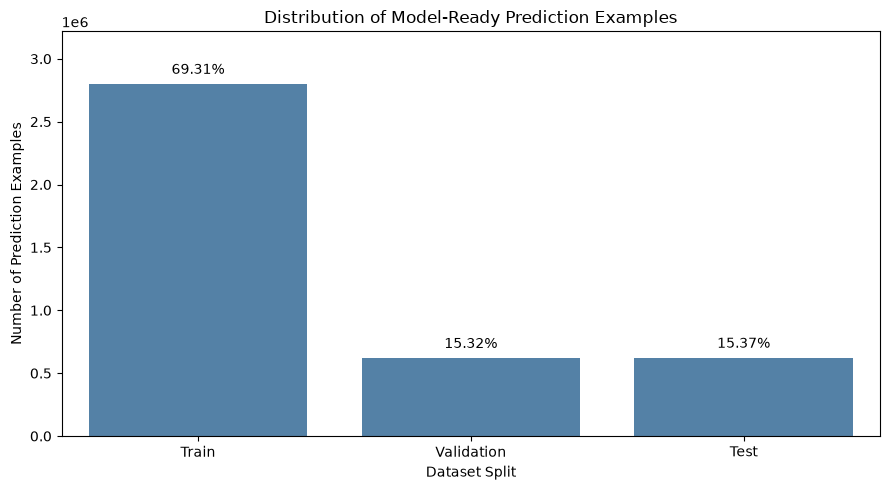

,Split,Observations,Percentage
0,Train,2798569,69.31
1,Validation,618726,15.32
2,Test,620433,15.37


In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare split distribution data
split_distribution = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Observations": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ]
})

# Calculate percentages
split_distribution["Percentage"] = (
    split_distribution["Observations"]
    / split_distribution["Observations"].sum()
    * 100
)

# Create visualization
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=split_distribution,
    x="Split",
    y="Observations",
    color="steelblue"
)

# Add percentage labels
for bar, percentage in zip(
    ax.patches,
    split_distribution["Percentage"]
):
    ax.annotate(
        f"{percentage:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Distribution of Model-Ready Prediction Examples")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Prediction Examples")
plt.ylim(0, split_distribution["Observations"].max() * 1.15)
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURES_DIR / "final_split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display and save summary table
display(split_distribution.round(2))

split_distribution.round(2).to_csv(
    TABLES_DIR / "final_split_distribution.csv",
    index=False
)


### Key Findings — Final Split Distribution

- The final dataset contains 4,037,728 prediction examples across three prediction horizons.
- Training accounts for 69.31% of the examples, validation for 15.32%, and testing for 15.37%.
- The resulting distribution closely matches the intended 70% / 15% / 15% chronological split.
- All splits preserve chronological ordering and use the team-approved 52-day dataset period.



### 14.2. Observation Loss During Preprocessing

**Objective:** Quantify the reduction in prediction examples caused by missing current observations, missing target labels, and missing historical lag features.

The analysis uses the selected 52-day period and excludes prediction examples whose target timestamps fall outside the dataset period.


Final model-ready examples: 4037728
Examples excluded at split boundaries: 4654


,Stage,Remaining Observations,Removed at Stage,Retained (%)
0,Initial 52-day examples,4492800,0,100.00
1,Valid target-time boundary,4490200,2600,99.94
2,Valid current features,4050723,439477,90.16
3,Valid target labels,4050070,653,90.15
4,Complete lag features,4042382,7688,89.97


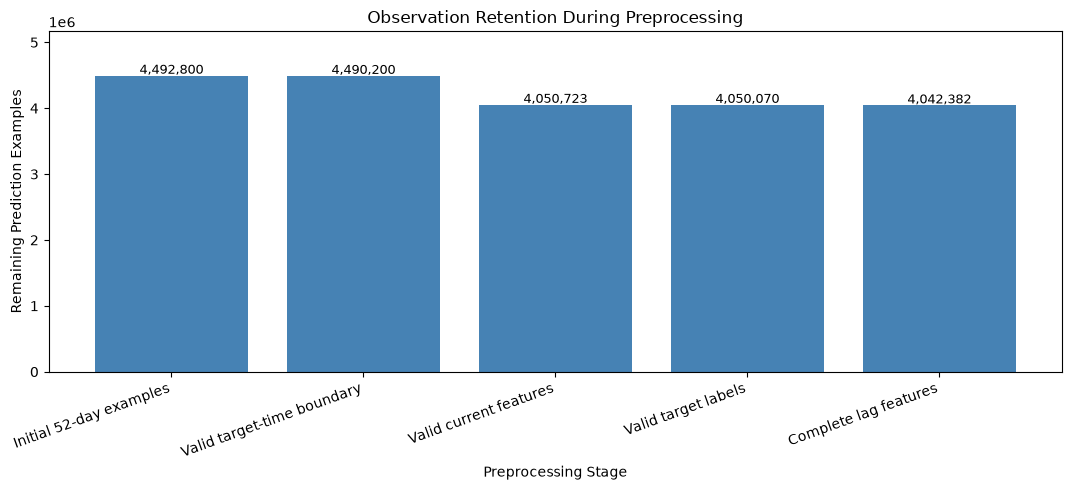

In [90]:

# Define the selected period and valid target-time boundaries
selected_period_mask = (
    model_df["time"].ge(DATASET_START)
    & model_df["time"].lt(DATASET_END)
)

within_period_mask = (
    selected_period_mask
    & model_df["target_time"].lt(DATASET_END)
)

# Count observations remaining after each filtering stage
observation_stages = [
    ("Initial 52-day examples", int(selected_period_mask.sum())),
    ("Valid target-time boundary", int(within_period_mask.sum())),
    ("Valid current features", int(
        (within_period_mask & valid_current).sum()
    )),
    ("Valid target labels", int(
        (within_period_mask & valid_current & valid_target).sum()
    )),
    ("Complete lag features", int(
        (within_period_mask & complete_case_mask).sum()
    ))
]

observation_loss_summary = pd.DataFrame(
    observation_stages,
    columns=["Stage", "Remaining Observations"]
)

observation_loss_summary["Removed at Stage"] = (
    observation_loss_summary["Remaining Observations"]
    .shift(1)
    - observation_loss_summary["Remaining Observations"]
).fillna(0).astype(int)

observation_loss_summary["Retained (%)"] = (
    observation_loss_summary["Remaining Observations"]
    / observation_loss_summary["Remaining Observations"].iloc[0]
    * 100
).round(2)

# Verify that the final count matches all three datasets
final_observation_count = (
    len(train_df) + len(validation_df) + len(test_df)
)

# Additional examples removed at internal chronological boundaries
split_boundary_loss = (
    observation_loss_summary["Remaining Observations"].iloc[-1]
    - final_observation_count
)

print("Final model-ready examples:", final_observation_count)
print("Examples excluded at split boundaries:", split_boundary_loss)

assert split_boundary_loss >= 0

display(observation_loss_summary)

# Export the summary table
observation_loss_summary.to_csv(
    TABLES_DIR / "observation_loss_summary.csv",
    index=False
)

# Visualize remaining observations at each preprocessing stage
plt.figure(figsize=(11, 5))

bars = plt.bar(
    observation_loss_summary["Stage"],
    observation_loss_summary["Remaining Observations"],
    color="steelblue"
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30000,
        f"{bar.get_height():,.0f}",
        ha="center",
        fontsize=9
    )

plt.title("Observation Retention During Preprocessing")
plt.xlabel("Preprocessing Stage")
plt.ylabel("Remaining Prediction Examples")
plt.xticks(rotation=20, ha="right")
plt.ylim(
    0,
    observation_loss_summary["Remaining Observations"].max() * 1.15
)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "observation_loss_preprocessing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Key Findings — Observation Loss During Preprocessing

- The selected 52-day period initially contains 4,492,800 prediction examples across three horizons.
- Missing or invalid current features account for the largest reduction, removing 439,477 examples after the target-time boundary check.
- Complete-case filtering removes only 7,688 additional examples due to missing historical lag features.
- An additional 4,654 examples are excluded at internal chronological split boundaries to prevent target leakage.
- The final datasets retain 4,037,728 prediction examples, approximately 89.87% of the initial examples.



### 14.3. Missing Values per Feature

**Objective:** Examine missing values across candidate input features before complete-case filtering and verify that no missing feature values remain in the final datasets.

The initial analysis uses the 52-day station-time dataset, counting each timestamp only once rather than repeating it across prediction horizons.


,Feature,Missing Before Filtering,Missing Rate (%),Missing After Filtering
0,station_id,0,0.00,0
1,hour,0,0.00,0
2,day_of_week,0,0.00,0
3,is_weekend,0,0.00,0
4,current_idle,146579,9.79,0
5,current_busy,146579,9.79,0
6,station_capacity,0,0.00,0
7,occupancy_rate,146579,9.79,0
8,idle_lag_5,146669,9.79,0
9,idle_lag_10,146759,9.80,0


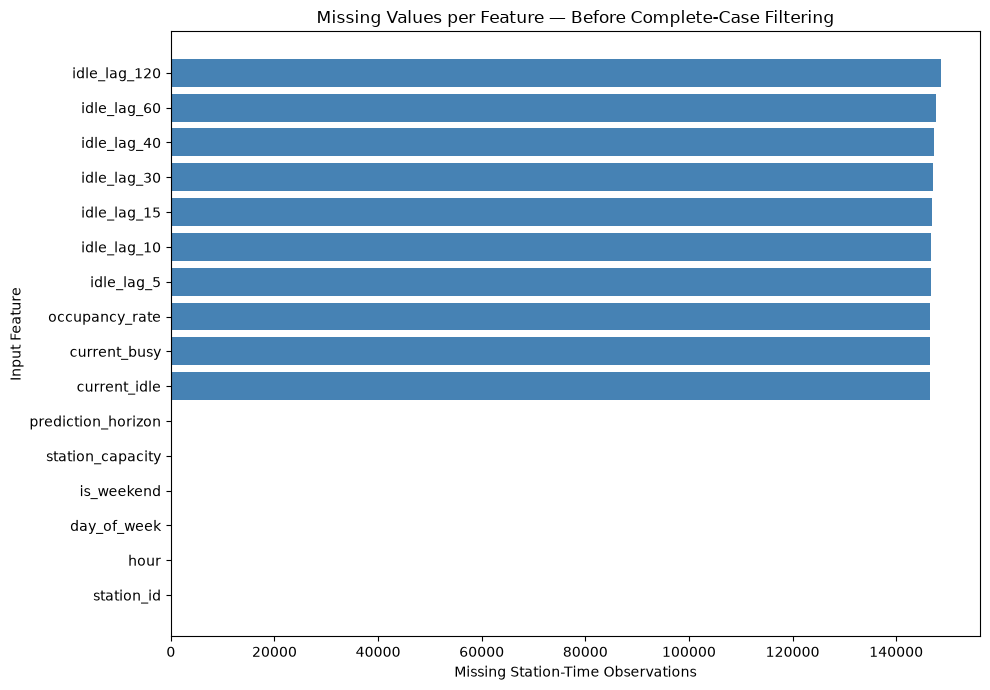

All final input features contain zero missing values.


In [91]:

# Select the approved 52-day period from the base dataset
base_time = df.index.get_level_values("time")

base_period_mask = (
    (base_time >= DATASET_START)
    & (base_time < DATASET_END)
)

# station_id and prediction_horizon do not have missing values
# in the constructed horizon-based dataset
base_feature_columns = [
    col for col in feature_columns
    if col not in ["station_id", "prediction_horizon"]
]

# Count missing values before complete-case filtering
missing_counts = (
    df.loc[base_period_mask, base_feature_columns]
    .isna()
    .sum()
)

base_observation_count = int(base_period_mask.sum())

missing_feature_summary = pd.DataFrame({
    "Feature": feature_columns,
    "Missing Before Filtering": [
        int(missing_counts.get(feature, 0))
        for feature in feature_columns
    ]
})

missing_feature_summary["Missing Rate (%)"] = (
    missing_feature_summary["Missing Before Filtering"]
    / base_observation_count * 100
).round(2)

# Final datasets must contain no missing input features
missing_feature_summary["Missing After Filtering"] = [
    int(sum(
        dataset[feature].isna().sum()
        for dataset in final_datasets.values()
    ))
    for feature in feature_columns
]

# Display and export
display(missing_feature_summary)

missing_feature_summary.to_csv(
    TABLES_DIR / "missing_values_per_feature.csv",
    index=False
)

# Visualize missing values before filtering
plot_data = missing_feature_summary.sort_values(
    "Missing Before Filtering",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Missing Before Filtering"],
    color="steelblue"
)

plt.title("Missing Values per Feature — Before Complete-Case Filtering")
plt.xlabel("Missing Station-Time Observations")
plt.ylabel("Input Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missing_values_per_feature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Verify final feature completeness
assert (
    missing_feature_summary["Missing After Filtering"] == 0
).all(), "Missing feature values remain in the final datasets."

print("All final input features contain zero missing values.")



### Key Findings — Missing Values per Feature

- The selected 52-day period contains 146,579 missing current idle and busy observations (9.79%).
- Missing values in historical lag features increase slightly with longer lag intervals, reaching 148,739 observations (9.93%) for the 120-minute lag.
- Temporal features, station capacity, station ID, and prediction horizon contain no missing values.
- Complete-case filtering successfully removes all examples with missing input features from the final training, validation, and test datasets.



### 14.4. Target Class Distribution by Split

**Objective:** Compare the available and unavailable target class distributions across training, validation, and test datasets.

The natural class imbalance is preserved. No oversampling, undersampling, or class balancing is applied during shared preprocessing.


,Split,Available (1),Unavailable (0),Available (%),Unavailable (%)
0,Train,2669770,128799,95.40,4.60
1,Validation,592861,25865,95.82,4.18
2,Test,593905,26528,95.72,4.28


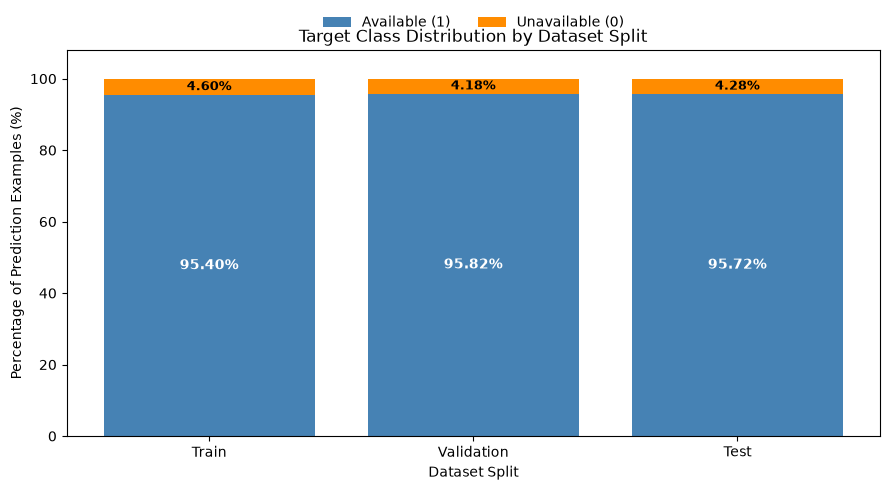

In [92]:


# Calculate target class distribution for each split
class_distribution_results = []

for split_name, dataset in final_datasets.items():

    available = int((dataset["target"] == 1).sum())
    unavailable = int((dataset["target"] == 0).sum())
    total = len(dataset)

    class_distribution_results.append({
        "Split": split_name,
        "Available (1)": available,
        "Unavailable (0)": unavailable,
        "Available (%)": round(available / total * 100, 2),
        "Unavailable (%)": round(unavailable / total * 100, 2)
    })

class_distribution_summary = pd.DataFrame(
    class_distribution_results
)

# Display and export summary table
display(class_distribution_summary)

class_distribution_summary.to_csv(
    TABLES_DIR / "class_distribution_by_split.csv",
    index=False
)

# Prepare percentage-based visualization
x = np.arange(len(class_distribution_summary))

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x,
    class_distribution_summary["Available (%)"],
    label="Available (1)",
    color="steelblue"
)

ax.bar(
    x,
    class_distribution_summary["Unavailable (%)"],
    bottom=class_distribution_summary["Available (%)"],
    label="Unavailable (0)",
    color="darkorange"
)

# Add percentage labels for both classes
for i, row in class_distribution_summary.iterrows():

    ax.text(
        i,
        row["Available (%)"] / 2,
        f'{row["Available (%)"]:.2f}%',
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

    ax.text(
        i,
        row["Available (%)"] + row["Unavailable (%)"] / 2,
        f'{row["Unavailable (%)"]:.2f}%',
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

# Customize chart
ax.set_xticks(x)
ax.set_xticklabels(class_distribution_summary["Split"])

ax.set_ylim(0, 108)
ax.set_ylabel("Percentage of Prediction Examples (%)")
ax.set_xlabel("Dataset Split")
ax.set_title("Target Class Distribution by Dataset Split")

# Position legend above the plot to avoid label overlap
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

plt.tight_layout()

# Save figure
plt.savefig(
    FIGURES_DIR / "class_distribution_by_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 14.5. Target Class Distribution by Prediction Horizon

**Objective:** Analyze the distribution of available and unavailable target classes across the 30-, 40-, and 60-minute prediction horizons for each chronological split.

This analysis examines whether class imbalance changes across prediction horizons while preserving the natural target distribution.


,Split,Prediction Horizon (min),Observations,Available (1),Unavailable (0),Available (%),Unavailable (%)
0,Train,30,933098,890169,42929,95.40,4.60
1,Train,40,932916,889983,42933,95.40,4.60
2,Train,60,932555,889618,42937,95.40,4.60
3,Validation,30,206482,197847,8635,95.82,4.18
4,Validation,40,206302,197677,8625,95.82,4.18
5,Validation,60,205942,197337,8605,95.82,4.18
6,Test,30,207065,198208,8857,95.72,4.28
7,Test,40,206874,198028,8846,95.72,4.28
8,Test,60,206494,197669,8825,95.73,4.27


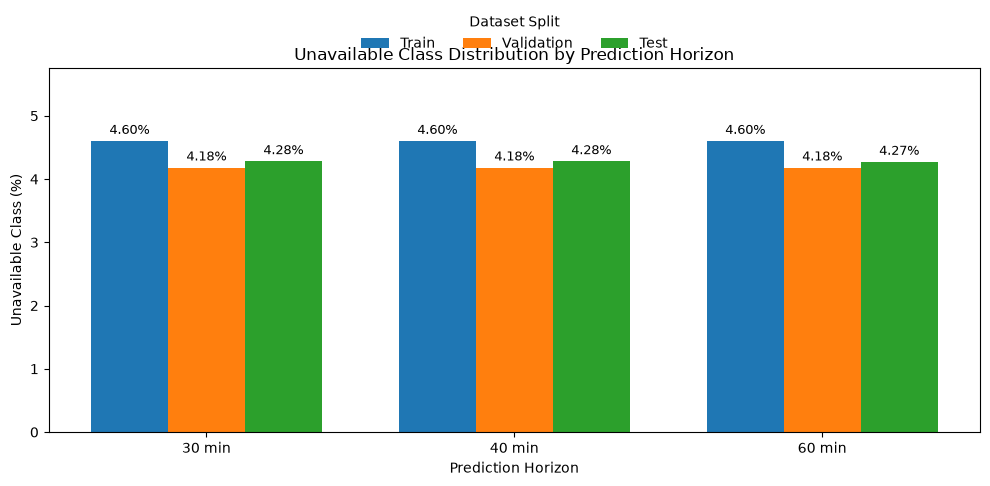

In [93]:

# Calculate target class distribution by split and prediction horizon
horizon_class_results = []

for split_name, dataset in final_datasets.items():

    for horizon in prediction_horizons:

        subset = dataset[
            dataset["prediction_horizon"] == horizon
        ]

        available = int((subset["target"] == 1).sum())
        unavailable = int((subset["target"] == 0).sum())
        total = len(subset)

        horizon_class_results.append({
            "Split": split_name,
            "Prediction Horizon (min)": horizon,
            "Observations": total,
            "Available (1)": available,
            "Unavailable (0)": unavailable,
            "Available (%)": round(
                available / total * 100, 2
            ),
            "Unavailable (%)": round(
                unavailable / total * 100, 2
            )
        })

horizon_class_summary = pd.DataFrame(
    horizon_class_results
)

# Display and export the summary table
display(horizon_class_summary)

horizon_class_summary.to_csv(
    TABLES_DIR / "class_distribution_by_horizon.csv",
    index=False
)

# Visualize the unavailable class percentage
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(prediction_horizons))
width = 0.25

for i, split_name in enumerate(["Train", "Validation", "Test"]):

    subset = horizon_class_summary[
        horizon_class_summary["Split"] == split_name
    ].sort_values("Prediction Horizon (min)")

    positions = x + (i - 1) * width

    bars = ax.bar(
        positions,
        subset["Unavailable (%)"],
        width=width,
        label=split_name
    )

    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

# Configure chart labels and layout
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{horizon} min" for horizon in prediction_horizons]
)

ax.set_xlabel("Prediction Horizon")
ax.set_ylabel("Unavailable Class (%)")
ax.set_title("Unavailable Class Distribution by Prediction Horizon")

ax.set_ylim(
    0,
    horizon_class_summary["Unavailable (%)"].max() * 1.25
)

ax.legend(
    title="Dataset Split",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=3,
    frameon=False
)

plt.tight_layout()

# Save figure
plt.savefig(
    FIGURES_DIR / "class_distribution_by_horizon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Key Findings — Target Class Distribution by Prediction Horizon

- The unavailable class accounts for approximately 4.60% of training, 4.18% of validation, and 4.27–4.28% of test examples across all prediction horizons.
- Class distributions remain highly consistent across the 30-, 40-, and 60-minute prediction horizons.
- The number of valid prediction examples decreases slightly as the prediction horizon increases due to target-time boundary restrictions.
- Similar class distributions do not necessarily imply similar prediction difficulty across horizons.
- The natural class imbalance is preserved for model-specific handling in subsequent development stages.



### 14.6. Station Coverage by Split

**Objective:** Compare the number of stations represented in each final dataset and identify stations that were not observed during training.

Station coverage is calculated using model-ready observations for the 30-minute prediction horizon. Unseen stations are retained in validation and test datasets.


,Split,Total Stations,Seen Stations,Unseen Stations,Coverage of Original 100 Stations (%)
0,Train,91,91,0,91.0
1,Validation,90,89,1,90.0
2,Test,93,91,2,93.0


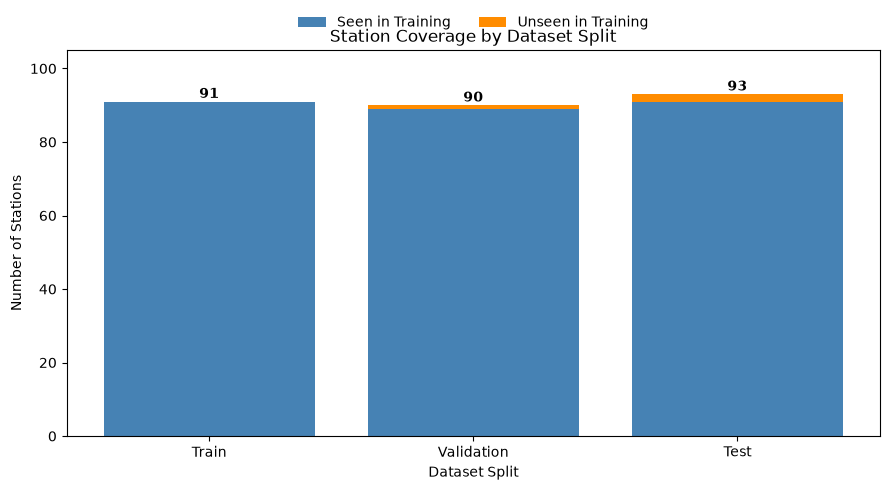

In [94]:

# Calculate station coverage using the 30-minute horizon
train_station_ids = set(train_df["station_id"].unique())

station_coverage_results = []

for split_name, dataset in final_datasets.items():

    subset = dataset[
        dataset["prediction_horizon"] == 30
    ]

    station_ids = set(subset["station_id"].unique())
    unseen_ids = station_ids - train_station_ids

    station_coverage_results.append({
        "Split": split_name,
        "Total Stations": len(station_ids),
        "Seen Stations": len(station_ids - unseen_ids),
        "Unseen Stations": len(unseen_ids),
        "Coverage of Original 100 Stations (%)": round(
            len(station_ids) / 100 * 100, 2
        )
    })

station_coverage_summary = pd.DataFrame(
    station_coverage_results
)

display(station_coverage_summary)

# Export summary
station_coverage_summary.to_csv(
    TABLES_DIR / "station_coverage_by_split.csv",
    index=False
)

# Visualize seen and unseen stations
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(station_coverage_summary))

ax.bar(
    x,
    station_coverage_summary["Seen Stations"],
    color="steelblue",
    label="Seen in Training"
)

ax.bar(
    x,
    station_coverage_summary["Unseen Stations"],
    bottom=station_coverage_summary["Seen Stations"],
    color="darkorange",
    label="Unseen in Training"
)

# Add total station labels
for i, row in station_coverage_summary.iterrows():
    ax.text(
        i,
        row["Total Stations"] + 1,
        str(int(row["Total Stations"])),
        ha="center",
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(station_coverage_summary["Split"])
ax.set_ylim(0, 105)

ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Stations")
ax.set_title("Station Coverage by Dataset Split")

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "station_coverage_by_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Key Findings — Station Coverage by Split

- The final training, validation, and test datasets contain 91, 90, and 93 stations, respectively.
- Validation contains one station unseen during training (1948), while test contains two unseen stations (1790 and 1948).
- All unseen stations are retained for separate generalization analysis.
- The primary objective remains future availability prediction for existing stations.
- Station representation is distinct from timestamp-level data coverage.



## 15. Reusable Preprocessing Module

The shared preprocessing pipeline is implemented in `src/preprocessing.py`.

It reproduces the team-approved feature engineering, target generation, complete-case filtering, and chronological train/validation/test splits.

The module output is compared with the notebook-generated datasets to verify consistency.


In [95]:

import preprocessing as pp
import importlib

# Reload the module after saving changes
importlib.reload(pp)

# Run the shared preprocessing pipeline
module_train, module_validation, module_test = (
    pp.run_preprocessing()
)

# Compare module and notebook results
module_comparison = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Notebook Observations": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Module Observations": [
        len(module_train),
        len(module_validation),
        len(module_test)
    ]
})

module_comparison["Match"] = (
    module_comparison["Notebook Observations"]
    == module_comparison["Module Observations"]
)

display(module_comparison)

# Verify exact dataset equality, including values and row order
for notebook_df, module_df in [
    (train_df, module_train),
    (validation_df, module_validation),
    (test_df, module_test)
]:
    pd.testing.assert_frame_equal(
        notebook_df,
        module_df,
        check_dtype=False
    )

assert module_comparison["Match"].all()

module_comparison.to_csv(
    TABLES_DIR / "preprocessing_module_comparison.csv",
    index=False
)

print("Shared preprocessing module matches notebook datasets.")


,Split,Notebook Observations,Module Observations,Match
0,Train,2798569,2798569,True
1,Validation,618726,618726,True
2,Test,620433,620433,True


Shared preprocessing module matches notebook datasets.



## 16. Export Model-Ready Datasets

**Objective:** Export the validated training, validation, and test datasets in Parquet format for shared machine learning development.

All datasets contain the same 16 candidate input features, binary target labels, and prediction timestamps.

Processed datasets are stored locally and must not be committed to GitHub. The shared preprocessing module allows team members to regenerate identical datasets.


In [96]:

# Export final model-ready datasets
export_datasets = {
    "train": module_train,
    "validation": module_validation,
    "test": module_test
}

export_results = []

for name, dataset in export_datasets.items():

    file_path = PROCESSED_DIR / f"{name}.parquet"

    # Save the complete dataset
    dataset.to_parquet(
        file_path,
        engine="pyarrow",
        index=False
    )

    # Read the exported file to verify its contents
    reloaded = pd.read_parquet(
        file_path,
        engine="pyarrow"
    )

    pd.testing.assert_frame_equal(
        dataset,
        reloaded
    )

    export_results.append({
        "Dataset": name,
        "File": file_path.name,
        "Observations": len(reloaded),
        "Stations": reloaded["station_id"].nunique(),
        "Input Features": len(pp.FEATURE_COLUMNS),
        "File Size (MB)": round(
            file_path.stat().st_size / (1024 ** 2), 2
        ),
        "Verified": True
    })

export_summary = pd.DataFrame(export_results)

display(export_summary)

# Save export verification
export_summary.to_csv(
    TABLES_DIR / "parquet_export_summary.csv",
    index=False
)

print("All model-ready datasets exported and verified successfully.")


,Dataset,File,Observations,Stations,Input Features,File Size (MB),Verified
0,train,train.parquet,2798569,91,16,5.19,True
1,validation,validation.parquet,618726,90,16,1.12,True
2,test,test.parquet,620433,93,16,1.08,True


All model-ready datasets exported and verified successfully.



## 17. Findings & Conclusion

### Dataset Selection

The 52-day period (December 1, 2022 – January 21, 2023) was selected based on data quality and temporal coverage analysis.

The full 90-day dataset has a missing observation rate of 25.46%, compared with 9.79% for the selected 52-day period. The shorter period also provides more consistent coverage across training, validation, and test intervals.

**Limitation:** The selected period excludes the final 38 days of the original dataset. Consequently, the initial model evaluation may not fully represent lower-coverage periods. Data from January 22 – February 28, 2023, is preserved for additional robustness evaluation after final model selection.

### Feature Engineering

A total of 16 candidate input features were prepared, including temporal features, current charger availability, station capacity, occupancy rate, historical idle counts, and prediction horizon.

Binary target labels were generated for 30-, 40-, and 60-minute prediction horizons. Missing future availability observations were not incorrectly assigned to the unavailable class.

### Missing Data Handling

The team selected complete-case filtering after comparing it with a missing-aware alternative.

The final datasets contain no missing input features or target labels. The resulting preprocessing pipeline retains 4,037,728 prediction examples.

### Chronological Data Splitting

The final datasets were divided chronologically:

- Training: December 1, 2022 – January 5, 2023
- Validation: January 6 – January 13, 2023
- Testing: January 14 – January 21, 2023

The resulting observation distribution is 69.31% training, 15.32% validation, and 15.37% testing.

Prediction timestamps and target timestamps were checked to prevent cross-split target leakage.

### Class Imbalance

The unavailable class represents approximately 4.60% of training, 4.18% of validation, and 4.28% of test examples.

The natural class distribution was preserved. Class imbalance will be addressed during model development and evaluation without modifying validation or test distributions.

### Station Coverage and Unseen Stations

The final datasets represent 91 training stations, 90 validation stations, and 93 test stations.

Station 1948 is unseen during training but appears in validation and testing. Station 1790 is also unseen during training and appears in testing.

These stations are retained. The project's primary objective is future availability prediction for existing stations, while unseen-station performance will be evaluated separately.

### Validation and Reproducibility

All final structural validations passed, including binary target checks, feature completeness, chronological boundaries, target-time alignment, duplicate detection, and forbidden input feature checks.

The shared preprocessing pipeline is implemented in `src/preprocessing.py`. Its outputs were verified to match the notebook-generated datasets.

Training, validation, and test datasets were exported to Parquet format and successfully verified after reloading.

### Conclusion

Step 2 produced consistent, validated, and reproducible model-ready datasets for subsequent machine learning development.

The datasets are ready to serve as shared inputs for Logistic Regression, Random Forest, XGBoost, and baseline models in Step 3.



## 18. Shared Dataset Contract & Model Development Preparation

### 18.1. Dataset Schema & Data Types

**Objective:** Document the exact column names, Pandas data types, and roles of the final model-ready datasets.

This schema serves as the common data contract for Logistic Regression, Random Forest, XGBoost, and LightGBM development.

All models must use the shared `FEATURE_COLUMNS` list. Timestamp columns are retained as metadata and must not be included in model inputs.


In [97]:

# Verify the common feature list
assert feature_columns == pp.FEATURE_COLUMNS
assert len(pp.FEATURE_COLUMNS) == 16

# Verify column names and dtypes are consistent across splits
assert train_df.columns.tolist() == validation_df.columns.tolist()
assert train_df.columns.tolist() == test_df.columns.tolist()

assert train_df.dtypes.equals(validation_df.dtypes)
assert train_df.dtypes.equals(test_df.dtypes)

# Define the role of each dataset column
def get_column_role(column):
    if column in pp.FEATURE_COLUMNS:
        return "Input Feature"
    elif column == "target":
        return "Target Label"
    elif column in ["time", "target_time"]:
        return "Evaluation Metadata"
    return "Other"

# Generate the dataset schema
model_input_schema = pd.DataFrame({
    "Column": train_df.columns,
    "Pandas Dtype": [
        str(train_df[column].dtype)
        for column in train_df.columns
    ],
    "Role": [
        get_column_role(column)
        for column in train_df.columns
    ]
})

# Identify categorical features
model_input_schema["Categorical"] = (
    model_input_schema["Column"].eq("station_id")
)

# Display results
display(model_input_schema)

# Save the shared schema
model_input_schema.to_csv(
    TABLES_DIR / "model_input_schema.csv",
    index=False
)

print("Input features:", len(pp.FEATURE_COLUMNS))
print("Total dataset columns:", len(train_df.columns))
print("Dataset schema is consistent across all splits.")


,Column,Pandas Dtype,Role,Categorical
0,station_id,int32,Input Feature,True
1,time,datetime64[us],Evaluation Metadata,False
2,target_time,datetime64[us],Evaluation Metadata,False
3,hour,int32,Input Feature,False
4,day_of_week,int32,Input Feature,False
5,is_weekend,int64,Input Feature,False
6,current_idle,float32,Input Feature,False
7,current_busy,float32,Input Feature,False
8,station_capacity,int64,Input Feature,False
9,occupancy_rate,float64,Input Feature,False


Input features: 16
Total dataset columns: 19
Dataset schema is consistent across all splits.



### Key Findings — Dataset Schema

- The final datasets contain 19 columns: 16 input features, two evaluation metadata columns, and one binary target column.
- Column names and Pandas data types are identical across training, validation, and test datasets.
- `station_id` is stored as `int32` but must be treated as a categorical feature during model development.
- The target is stored as `float64` and contains only binary labels (0 and 1).
- The dataset schema is documented in `model_input_schema.csv` for consistent use across all machine learning models.



### 18.2. Training Station IDs

**Objective:** Export the training station identifiers and verify unseen stations in validation and test datasets.

The training station list defines the common seen/unseen grouping for model evaluation. Unseen station observations are retained in all datasets.


In [98]:

# Get station IDs present in training
training_station_ids = sorted(
    train_df["station_id"].unique().tolist()
)

training_station_summary = pd.DataFrame({
    "station_id": training_station_ids
})

# Identify unseen stations
train_station_set = set(training_station_ids)

validation_unseen = sorted(
    set(validation_df["station_id"].unique()) - train_station_set
)

test_unseen = sorted(
    set(test_df["station_id"].unique()) - train_station_set
)

# Validate expected station coverage
assert len(training_station_ids) == 91
assert validation_unseen == [1948]
assert test_unseen == [1790, 1948]

# Display results
print("Training stations:", len(training_station_ids))
print("Unseen validation stations:", validation_unseen)
print("Unseen test stations:", test_unseen)

display(training_station_summary.head(10))

# Export the complete training station list
training_station_summary.to_csv(
    TABLES_DIR / "training_station_ids.csv",
    index=False
)

print("Training station identifiers exported successfully.")


Training stations: 91
Unseen validation stations: [np.int32(1948)]
Unseen test stations: [np.int32(1790), np.int32(1948)]


,station_id
0,1703
1,1712
2,1714
3,1717
4,1720
5,1729
6,1730
7,1743
8,1751
9,1755


Training station identifiers exported successfully.



### Key Findings — Training Station IDs

- The training dataset contains 91 unique stations.
- Station 1948 appears in validation but is unseen during training.
- Stations 1790 and 1948 appear in testing but are unseen during training.
- The complete list of training station identifiers is exported to `training_station_ids.csv`.
- Unseen stations are retained in the evaluation datasets and will be analyzed separately.



### 18.3. Dataset Configuration & Version Metadata

**Objective:** Export a versioned dataset configuration containing the approved preprocessing decisions, feature list, target definition, prediction horizons, split boundaries, and final observation counts.

This metadata supports consistent dataset usage and reproducibility across all machine learning models.


In [99]:

import json

# Define the common dataset contract
dataset_config = {
    "dataset_version": "VOLTAHEAD-DATA-V1",
    "source_dataset": "UrbanEV",
    "preprocessing_module": "src/preprocessing.py",
    "dataset_period": {
        "start": "2022-12-01",
        "end_inclusive": "2023-01-21",
        "end_exclusive": "2023-01-22"
    },
    "missing_value_strategy": "complete_case",
    "prediction_horizons_minutes": pp.PREDICTION_HORIZONS,
    "feature_columns": pp.FEATURE_COLUMNS,
    "target_definition": {
        "column": "target",
        "available_class": 1,
        "unavailable_class": 0,
        "missing_future_idle": "excluded"
    },
    "splits": {
        "train": {
            "start": "2022-12-01",
            "end_exclusive": "2023-01-06",
            "observations": len(train_df),
            "stations": int(train_df["station_id"].nunique())
        },
        "validation": {
            "start": "2023-01-06",
            "end_exclusive": "2023-01-14",
            "observations": len(validation_df),
            "stations": int(validation_df["station_id"].nunique())
        },
        "test": {
            "start": "2023-01-14",
            "end_exclusive": "2023-01-22",
            "observations": len(test_df),
            "stations": int(test_df["station_id"].nunique())
        }
    },
    "evaluation": {
        "primary_objective": "future availability at existing stations",
        "unseen_validation_stations": [int(x) for x in validation_unseen],
        "unseen_test_stations": [int(x) for x in test_unseen],
        "probability_output": "P(Available=1)",
        "initial_threshold": 0.5,
        "random_seed": 42
    },
    "robustness_period": {
        "start": "2023-01-22",
        "end_inclusive": "2023-02-28",
        "purpose": "post-selection robustness evaluation"
    }
}

# Export configuration JSON
config_path = TABLES_DIR / "dataset_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(dataset_config, f, indent=4)

# Read back and validate
with open(config_path, "r", encoding="utf-8") as f:
    saved_config = json.load(f)

assert saved_config["feature_columns"] == pp.FEATURE_COLUMNS
assert saved_config["splits"]["train"]["observations"] == len(train_df)
assert saved_config["splits"]["validation"]["observations"] == len(validation_df)
assert saved_config["splits"]["test"]["observations"] == len(test_df)

print("Dataset version:", saved_config["dataset_version"])
print("Input features:", len(saved_config["feature_columns"]))
print("Prediction horizons:", saved_config["prediction_horizons_minutes"])
print("Dataset configuration exported successfully.")
print("Saved file:", config_path)


Dataset version: VOLTAHEAD-DATA-V1
Input features: 16
Prediction horizons: [30, 40, 60]
Dataset configuration exported successfully.
Saved file: /Users/zumra/Desktop/classes/26-27/fall 2026/ISE308/VoltAhead/outputs/tables/dataset_config.json



### 18.4. Internal Chronological Split Validation

**Objective:** Validate the common training-only chronological periods used for model fitting, hyperparameter tuning, probability calibration, and classification threshold optimization.

All internal periods preserve chronological ordering. Prediction timestamps and target timestamps must remain within the corresponding internal boundaries.

The analysis reports observation counts, station coverage, and available/unavailable class distributions for each prediction horizon.


In [100]:

# Define shared internal chronological periods
INTERNAL_SPLITS = {
    "Model Fit": ("2022-12-01", "2022-12-24"),
    "Tuning": ("2022-12-24", "2022-12-30"),
    "Calibration": ("2022-12-30", "2023-01-03"),
    "Threshold": ("2023-01-03", "2023-01-06")
}

internal_datasets = {}
internal_results = []

for period_name, (start, end) in INTERNAL_SPLITS.items():

    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    # Prevent targets from crossing internal period boundaries
    period_mask = (
        train_df["time"].ge(start)
        & train_df["time"].lt(end)
        & train_df["target_time"].lt(end)
    )

    subset = train_df.loc[period_mask]
    internal_datasets[period_name] = subset

    for horizon in prediction_horizons:

        horizon_subset = subset[
            subset["prediction_horizon"] == horizon
        ]

        available = int(
            (horizon_subset["target"] == 1).sum()
        )

        unavailable = int(
            (horizon_subset["target"] == 0).sum()
        )

        total = len(horizon_subset)

        internal_results.append({
            "Period": period_name,
            "Horizon (min)": horizon,
            "Observations": total,
            "Stations": horizon_subset["station_id"].nunique(),
            "Available (1)": available,
            "Unavailable (0)": unavailable,
            "Unavailable Rate (%)": round(
                unavailable / total * 100, 2
            ) if total > 0 else np.nan
        })

internal_split_summary = pd.DataFrame(internal_results)

# Validate class representation
assert (internal_split_summary["Available (1)"] > 0).all()
assert (internal_split_summary["Unavailable (0)"] > 0).all()

# Validate target-time boundaries
for period_name, subset in internal_datasets.items():

    start, end = INTERNAL_SPLITS[period_name]
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    assert subset["time"].ge(start).all()
    assert subset["time"].lt(end).all()
    assert subset["target_time"].lt(end).all()

# Display and export
display(internal_split_summary)

internal_split_summary.to_csv(
    TABLES_DIR / "internal_split_summary.csv",
    index=False
)

print("All internal chronological periods validated successfully.")


,Period,Horizon (min),Observations,Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,Model Fit,30,596929,91,567617,29312,4.91
1,Model Fit,40,596747,91,567431,29316,4.91
2,Model Fit,60,596386,91,567066,29320,4.92
3,Tuning,30,155875,91,148953,6922,4.44
4,Tuning,40,155693,91,148781,6912,4.44
5,Tuning,60,155329,91,148437,6892,4.44
6,Calibration,30,102312,90,98561,3751,3.67
7,Calibration,40,102132,90,98387,3745,3.67
8,Calibration,60,101772,90,98039,3733,3.67
9,Threshold,30,76362,89,73484,2878,3.77


All internal chronological periods validated successfully.



### Key Findings — Internal Chronological Splits

- Four non-overlapping chronological periods were established within the training dataset for model fitting, hyperparameter tuning, probability calibration, and threshold optimization.
- All periods contain both target classes across the 30-, 40-, and 60-minute prediction horizons.
- Unavailable class rates range from approximately 3.67% to 4.92% across the internal periods.
- The calibration and threshold periods retain approximately 3,700 and 2,900 unavailable examples per horizon, respectively.
- Prediction timestamps and target timestamps remain within their assigned internal period boundaries.
- The approved internal splits can be used consistently by all machine learning models without modifying the shared train, validation, or test datasets.



### 18.5. Shared Development Sample Validation

**Objective:** Create and validate a deterministic training-only development sample for fast machine learning experiments.

The sample is selected from the approved Model Fit period by retaining every fourth five-minute timestamp. This preserves station-time grouping across prediction horizons and does not use target labels for sampling.

The development sample is intended for implementation testing and preliminary experiments only. Final model fitting uses the full approved fitting period.


In [101]:

# Use only the approved Model Fit period
fit_df = internal_datasets["Model Fit"]

# Create deterministic five-minute time-slot identifiers
time_slots = (
    (
        fit_df["time"]
        - pd.Timestamp("2022-12-01")
    ).dt.total_seconds() // 300
).astype("int64")

# Retain every fourth timestamp (25% temporal sample)
sample_mask = time_slots.mod(4).eq(0)

development_sample = fit_df.loc[sample_mask].copy()

# Summarize sampled observations by prediction horizon
sample_results = []

for horizon in prediction_horizons:

    original = fit_df[
        fit_df["prediction_horizon"] == horizon
    ]

    sampled = development_sample[
        development_sample["prediction_horizon"] == horizon
    ]

    unavailable = int((sampled["target"] == 0).sum())
    available = int((sampled["target"] == 1).sum())

    sample_results.append({
        "Horizon (min)": horizon,
        "Original Observations": len(original),
        "Sample Observations": len(sampled),
        "Sample Rate (%)": round(
            len(sampled) / len(original) * 100, 2
        ),
        "Stations": sampled["station_id"].nunique(),
        "Available (1)": available,
        "Unavailable (0)": unavailable,
        "Unavailable Rate (%)": round(
            unavailable / len(sampled) * 100, 2
        )
    })

development_sample_summary = pd.DataFrame(sample_results)

# Validate sample structure
assert set(development_sample["prediction_horizon"].unique()) == {
    30, 40, 60
}

assert development_sample["target"].isin([0, 1]).all()

assert (
    development_sample["target_time"]
    < pd.Timestamp("2022-12-24")
).all()

assert (
    development_sample_summary["Unavailable (0)"] > 0
).all()

# Display and export
display(development_sample_summary)

development_sample_summary.to_csv(
    TABLES_DIR / "development_sample_summary.csv",
    index=False
)

print("Development sample observations:", len(development_sample))
print("Development sample validated successfully.")


,Horizon (min),Original Observations,Sample Observations,Sample Rate (%),Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,30,596929,149277,25.01,91,141892,7385,4.95
1,40,596747,149190,25.00,91,141980,7210,4.83
2,60,596386,149100,25.00,91,141891,7209,4.84


Development sample observations: 447567
Development sample validated successfully.



### Key Findings — Shared Development Sample

- A deterministic 25% development sample was created from the approved Model Fit period.
- The sample contains 447,567 observations across the 30-, 40-, and 60-minute prediction horizons.
- All 91 training stations are represented.
- Each horizon retains more than 7,000 unavailable observations.
- The overall unavailable-class rate is approximately 4.87%, which is close to the original Model Fit distribution.
- Sampling is based on five-minute timestamps rather than target labels, preserving the shared station-time structure.
- The development sample is approved for rapid model experiments and implementation checks, while final model fitting must use the full approved fitting period.
